# Data exploration - Google (GOOGL) stock data



In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = "../data"
RESULTS_DIR = "../results"
CSV_PATH = os.path.join(BASE_DIR, "GOOGL.csv")
# put GOOGL.csv in a folder named data, same level as the README, in your clone of the repo

WINDOW = 30
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15  # test = remaining 15%
FEATURES = ["Close"]  # minimum; try ["Open", "High", "Low", "Close", "Volume"] for multivariate

os.makedirs(RESULTS_DIR, exist_ok=True)


def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150)
    plt.show()

## 1. load

In [2]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("\nFirst rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)
print("\nSummary statistics:")
print(df.describe().T)

Shape: (4431, 7)

First rows:
         Date       Open       High        Low      Close  Adj Close    Volume
0  2004-08-19  50.050049  52.082081  48.028027  50.220219  50.220219  44659096
1  2004-08-20  50.555557  54.594597  50.300301  54.209209  54.209209  22834343
2  2004-08-23  55.430431  56.796799  54.579578  54.754753  54.754753  18256126
3  2004-08-24  55.675674  55.855858  51.836838  52.487488  52.487488  15247337
4  2004-08-25  52.532532  54.054054  51.991993  53.053055  53.053055   9188602

Data types:
Date             str
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

Summary statistics:
            count          mean           std            min           25%  \
Open       4431.0  6.930873e+02  6.451188e+02      49.644646  2.485586e+02   
High       4431.0  6.997356e+02  6.513312e+02      50.920921  2.508534e+02   
Low        4431.0  6.860788e+02  6.385795e+02      48.028027  2.458

## 2. sort

In [3]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print("\nDate range:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Chronological:", df["Date"].is_monotonic_increasing)
print("Duplicate dates:", df["Date"].duplicated().sum())


Date range: 2004-08-19 -> 2022-03-24
Chronological: True
Duplicate dates: 0


## 3. missing values

In [4]:
print("\nMissing values per column:")
print(df.isna().sum())
# also check for impossible values and large calendar gaps
print("Non-positive prices:", (df[["Open", "High", "Low", "Close"]] <= 0).sum().sum())
print("High < Low rows:", (df["High"] < df["Low"]).sum())
gaps = df["Date"].diff().dt.days
print("Largest gap between trading days:", int(gaps.max()), "days")
print("Close == Adj Close everywhere:", np.allclose(df["Close"], df["Adj Close"]))
# no missing values -> nothing to drop/impute. If any appeared, forward-fill would be
# justified for prices (last known price) and kept train-only safe since it looks backward.


Missing values per column:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64
Non-positive prices: 0
High < Low rows: 0
Largest gap between trading days: 5 days
Close == Adj Close everywhere: True


## 4. visual exploration

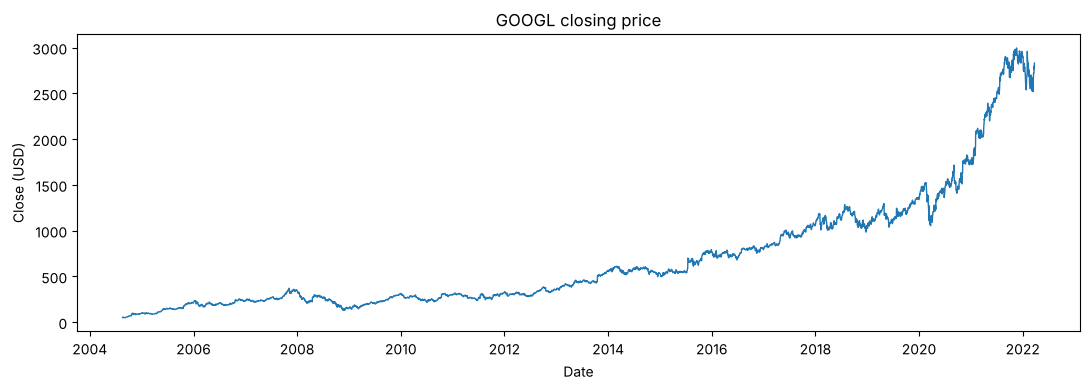

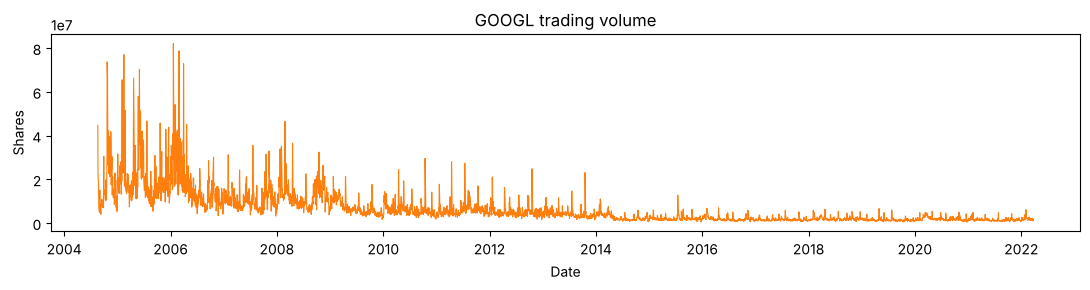

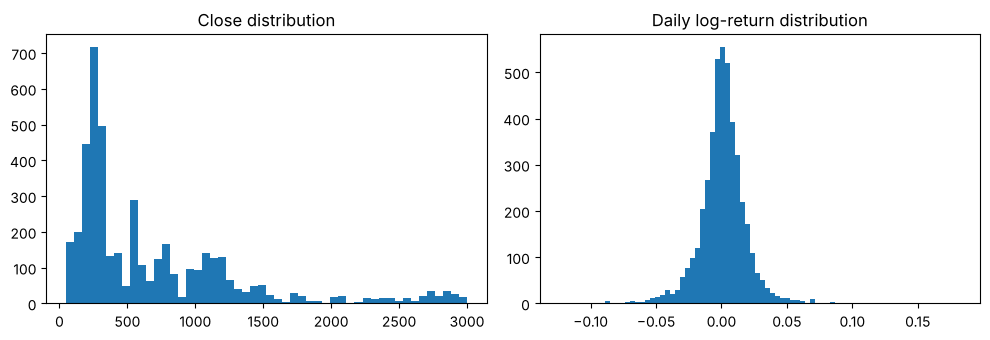


Correlation with Close:
Open      0.999808
High      0.999903
Low       0.999914
Close     1.000000
Volume   -0.454252
Name: Close, dtype: float64


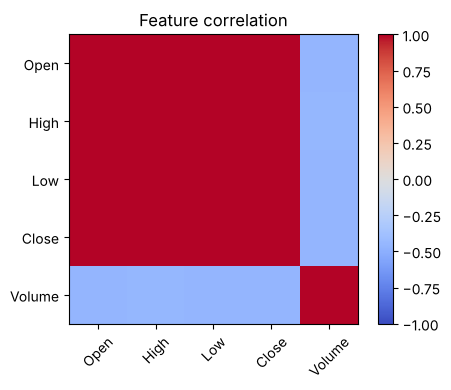

In [5]:
plt.figure(figsize=(11, 4))
plt.plot(df["Date"], df["Close"], linewidth=1)
plt.title("GOOGL closing price")
plt.xlabel("Date")
plt.ylabel("Close (USD)")
save("eda_close_price.png")

plt.figure(figsize=(11, 3))
plt.plot(df["Date"], df["Volume"], linewidth=0.8, color="tab:orange")
plt.title("GOOGL trading volume")
plt.xlabel("Date")
plt.ylabel("Shares")
save("eda_volume.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["Close"], bins=50)
axes[0].set_title("Close distribution")
axes[1].hist(np.log(df["Close"]).diff().dropna(), bins=80)
axes[1].set_title("Daily log-return distribution")
save("eda_distributions.png")

corr = df[["Open", "High", "Low", "Close", "Volume"]].corr()
print("\nCorrelation with Close:")
print(corr["Close"])
plt.figure(figsize=(5, 4))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.title("Feature correlation")
save("eda_correlation.png")

## 5. chronological split


Chronological split:
     Split  Rows Share      Start        End  Close mean  Close max
     Train  3101 70.0% 2004-08-19 2016-12-09      350.70     835.74
Validation   665 15.0% 2016-12-12 2019-08-05     1052.03    1296.20
      Test   665 15.0% 2019-08-06 2022-03-24     1930.84    2996.77


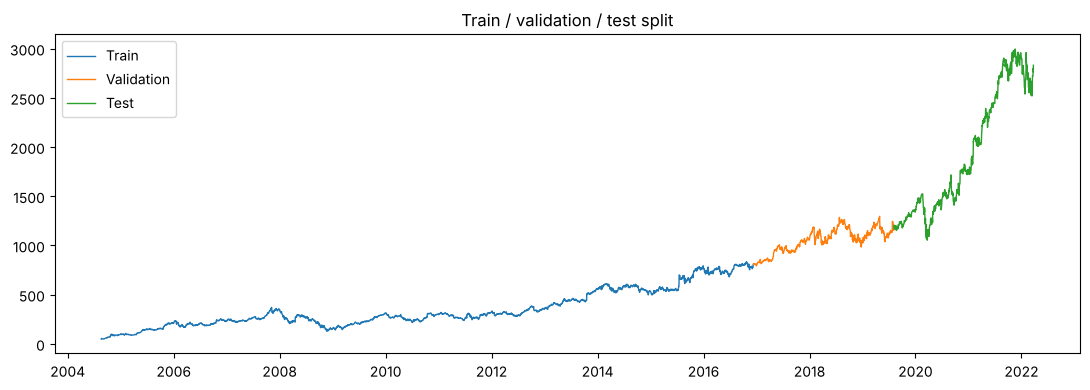

In [6]:
n = len(df)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))
splits = {
    "Train": df.iloc[:train_end],
    "Validation": df.iloc[train_end:val_end],
    "Test": df.iloc[val_end:],
}
rows = []
for name, part in splits.items():
    rows.append({
        "Split": name,
        "Rows": len(part),
        "Share": f"{len(part) / n:.1%}",
        "Start": part["Date"].min().date(),
        "End": part["Date"].max().date(),
        "Close mean": round(part["Close"].mean(), 2),
        "Close max": round(part["Close"].max(), 2),
    })
print("\nChronological split:")
print(pd.DataFrame(rows).to_string(index=False))
# note: test prices are far above the training range (stock keeps trending up),
# a scaler fit on train will give test values > 1 - worth discussing in the report.

plt.figure(figsize=(11, 4))
for name, part in splits.items():
    plt.plot(part["Date"], part["Close"], label=name, linewidth=1)
plt.title("Train / validation / test split")
plt.legend()
save("eda_split.png")

## 6. scaling (train only)

In [7]:
scaler = MinMaxScaler()
scaler.fit(splits["Train"][FEATURES])
scaled = {k: scaler.transform(v[FEATURES]) for k, v in splits.items()}
for k, v in scaled.items():
    print(f"{k:<10} scaled min={v.min():.3f} max={v.max():.3f}")

Train      scaled min=0.000 max=1.000
Validation scaled min=0.945 max=1.586
Test       scaled min=1.278 max=3.751


## 7. sequences

In [8]:
def make_sequences(values, window=WINDOW, target_col=FEATURES.index("Close")):
    """X[i] = days i..i+window-1, y[i] = Close on day i+window (next trading day)."""
    X, y = [], []
    for i in range(len(values) - window):
        X.append(values[i:i + window])
        y.append(values[i + window, target_col])
    return np.array(X), np.array(y)


# Each split is windowed on its own so no window crosses a split boundary.
# (Cost: the first 30 days of val/test produce no targets. Alternative is to
# prepend the previous 30 days of the earlier split as context - safe, since
# those are past observations, not future ones.)
seq = {k: make_sequences(v) for k, v in scaled.items()}

print("\nSequence shapes:")
for k, (X, y) in seq.items():
    print(f"{k:<10} X={X.shape}  y={y.shape}")


Sequence shapes:
Train      X=(3071, 30, 1)  y=(3071,)
Validation X=(635, 30, 1)  y=(635,)
Test       X=(635, 30, 1)  y=(635,)


## 8. sanity / leakage checks

In [9]:
X_tr, y_tr = seq["Train"]
assert X_tr.shape[1:] == (WINDOW, len(FEATURES))
assert len(X_tr) == len(y_tr)
# target of sequence i is the day right after its window
assert np.isclose(y_tr[0], scaled["Train"][WINDOW, 0])
assert np.allclose(X_tr[1][:-1], X_tr[0][1:])  # window slides by exactly one day
# split boundaries are strictly ordered in time
assert splits["Train"]["Date"].max() < splits["Validation"]["Date"].min()
assert splits["Validation"]["Date"].max() < splits["Test"]["Date"].min()
# scaler learned from train only
assert np.isclose(scaler.data_max_[0], splits["Train"]["Close"].max())
print("\nAll checks passed: shapes OK, order preserved, no future leakage.")


All checks passed: shapes OK, order preserved, no future leakage.


## 9. persistence baseline

In [10]:
# Required for the final comparison: predict tomorrow's close = today's close.
if FEATURES == ["Close"]:  # inverse transform below assumes the single-feature scaler
    for k in ("Validation", "Test"):
        X, y = seq[k]
        actual = scaler.inverse_transform(y.reshape(-1, 1)).ravel()
        pred = scaler.inverse_transform(X[:, -1, :]).ravel()
        mae = np.mean(np.abs(actual - pred))
        rmse = np.sqrt(np.mean((actual - pred) ** 2))
        print(f"Persistence baseline {k}: MAE={mae:.2f} USD  RMSE={rmse:.2f} USD")

Persistence baseline Validation: MAE=11.21 USD  RMSE=16.52 USD
Persistence baseline Test: MAE=25.34 USD  RMSE=36.21 USD
